# Taller: Introducción a Redes Neuronales Artificiales (RNA)
**Curso de Inteligencia Artificial**

En este notebook implementamos y explicamos **paso a paso cómo funciona una Red Neuronal Artificial** sin librerías de caja negra (sin PyTorch ni TensorFlow), usando únicamente **NumPy y Álgebra Lineal**.

---

### ¿Cómo funciona la Red Neuronal de este taller?
La red diseñada es un **Perceptrón Multicapa (MLP) de arquitectura 4–5–1**:
* **Capa de Entrada (4 neuronas):** Recibe las 4 variables de conducción:
  1. $x_1$: Velocidad (km/h)
  2. $x_2$: Calidad del terreno (0 a 10)
  3. $x_3$: Ángulo de visión / visibilidad (0 a 360°)
  4. $x_4$: Experiencia del conductor (km recorridos)
* **Capa Oculta (5 neuronas):** Transforma las 4 entradas mediante una matriz de pesos $W^{(1)} \in \mathbb{R}^{5 \times 4}$ y activación no lineal $\sigma(z)$.
* **Capa de Salida (1 neurona):** Pesa las 5 activaciones intermedias con $W^{(2)} \in \mathbb{R}^{1 \times 5}$ y bota la probabilidad final $\hat{y} \in [0, 1]$ de colisión.


## 1. Implementación de las Funciones Fundamentales de la Red Neuronal
Aquí definimos desde cero las 5 operaciones clave de una red neuronal:
1. `sigmoide(z)`: Función de activación que acota cualquier valor real al intervalo $(0, 1)$.
2. `escalar(X_raw, limites)`: Normalización Min-Max para poner todas las variables en la misma escala $[0, 1]$.
3. `propagar(X, W1, b1, W2, b2)`: El **Forward Pass** matricial de dos capas:
   $$Z^{(1)} = W^{(1)}X + b^{(1)}, \quad A^{(1)} = \sigma(Z^{(1)})$$
   $$Z^{(2)} = W^{(2)}A^{(1)} + b^{(2)}, \quad P = \sigma(Z^{(2)})$$
4. `clasificar(probabilidades, umbral)`: Regla de decisión $\hat{c} = 1$ si $P \ge \tau$, y $0$ en otro caso.
5. `entropia_cruzada(y, probabilidades)`: Función de pérdida de entropía cruzada binaria (BCE).


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. FUNCIÓN DE ACTIVACIÓN SIGMOIDE
def sigmoide(z):
    """Calcula sigma(z) = 1 / (1 + exp(-z)) protegiendo contra overflow."""
    z_seguro = np.clip(np.asarray(z, dtype=float), -500.0, 500.0)
    return 1.0 / (1.0 + np.exp(-z_seguro))

# 2. ESCALAMIENTO MIN-MAX
def escalar(X_raw, limites):
    """Normaliza las características dividiendo entre el límite máximo: x' = x / limites."""
    return np.asarray(X_raw, dtype=float) / np.asarray(limites, dtype=float)

# 3. PROPAGACIÓN HACIA ADELANTE (FORWARD PASS MATRICIAL)
def propagar(X, W1, b1, W2, b2):
    """
    Propaga las entradas X de dimensiones (d, N) a través de la red:
      - Z1 = W1 @ X + b1  -> forma (5, N)
      - A1 = sigmoide(Z1)  -> forma (5, N)
      - Z2 = W2 @ A1 + b2  -> forma (1, N)
      - P  = sigmoide(Z2)  -> forma (1, N)
    """
    X_mat = np.asarray(X, dtype=float)
    if X_mat.ndim == 1:
        X_mat = X_mat.reshape(-1, 1)
        
    b1_mat = np.asarray(b1, dtype=float).reshape(-1, 1)
    b2_mat = np.asarray(b2, dtype=float).reshape(-1, 1)
    
    # Capa oculta
    Z1 = W1 @ X_mat + b1_mat
    A1 = sigmoide(Z1)
    
    # Capa de salida
    Z2 = W2 @ A1 + b2_mat
    P  = sigmoide(Z2)
    
    return Z1, A1, Z2, P

# 4. DECISIÓN Y UMBRALIZACIÓN
def clasificar(probabilidades, umbral=0.5):
    """Convierte puntuaciones continuas en clases binarias {0, 1}."""
    return (np.asarray(probabilidades, dtype=float) >= float(umbral)).astype(int)

# 5. PÉRDIDA DE ENTROPÍA CRUZADA BINARIA (BCE)
def entropia_cruzada(y, probabilidades):
    """Calcula la pérdida media L = - (1/N) * sum( y*ln(p) + (1-y)*ln(1-p) )."""
    y_flat = np.asarray(y, dtype=float).ravel()
    p_flat = np.asarray(probabilidades, dtype=float).ravel()
    eps = 1e-15
    p_seguro = np.clip(p_flat, eps, 1.0 - eps)
    perdidas = -(y_flat * np.log(p_seguro) + (1.0 - y_flat) * np.log(1.0 - p_seguro))
    return float(np.mean(perdidas))

print("Funciones fundamentales de la Red Neuronal definidas exitosamente.")


Funciones fundamentales de la Red Neuronal definidas exitosamente.


## 2. Datos de Prueba y Parámetros de la Red
Definimos los 7 registros de conductores y las matrices de pesos $W^{(1)}$ y $W^{(2)}$ proporcionados en la clase ([11_IA_2026_2.pdf](file:///c:/Users/porru/OneDrive/Desktop/Inteligencia%20Artificial/Material%20Clase/11_IA_2026_2.pdf)):


In [2]:
# Matriz de entradas crudas (7 ejemplos en filas x 4 columnas)
# Columnas: [Velocidad (km/h), Terreno (0-10), Visión (grados), Experiencia (km)]
X_RAW = np.array([
    [65,  5, 180,  80000],  # Registro 1: No colisión (0)
    [120, 1,  72, 110000],  # Registro 2: Sí colisión (1)
    [8,   6, 288,  50000],  # Registro 3: No colisión (0)
    [50,  2, 324,   1600],  # Registro 4: Sí colisión (1)
    [25,  9,  36, 160000],  # Registro 5: No colisión (0)
    [80,  3, 120,   6000],  # Registro 6: Sí colisión (1)
    [40,  3, 360, 400000]   # Registro 7: No colisión (0)
], dtype=float)

# Etiquetas reales conocidas durante el entrenamiento (0 = No choca, 1 = Sí choca)
Y = np.array([0, 1, 0, 1, 0, 1, 0])

# Límites máximos para escalamiento Min-Max
LIMITES = np.array([120.0, 10.0, 360.0, 400000.0], dtype=float)

# Matriz de pesos de la capa oculta W^(1) (5 neuronas x 4 entradas)
W1 = np.array([
    [ 3.35, -5.82,  0.85, -4.35],
    [-3.94,  4.88, -1.83,  4.21],
    [ 2.43, -4.35,  0.36, -2.97],
    [-0.58,  1.30,  0.31,  1.40],
    [-3.34,  4.40, -0.75,  3.89]
], dtype=float)

# Matriz de pesos de la capa de salida W^(2) (1 neurona x 5 activaciones ocultas)
W2 = np.array([[8.45, -6.96, 6.28, -1.36, -6.16]], dtype=float)

# Sesgos (inicialmente ceros)
B1 = np.zeros((5, 1))
B2 = np.zeros((1, 1))

print("X_RAW shape:", X_RAW.shape)
print("W1 shape:", W1.shape, "(5 neuronas ocultas x 4 entradas)")
print("W2 shape:", W2.shape, "(1 neurona de salida x 5 entradas de capa oculta)")


X_RAW shape: (7, 4)
W1 shape: (5, 4) (5 neuronas ocultas x 4 entradas)
W2 shape: (1, 5) (1 neurona de salida x 5 entradas de capa oculta)


## 3. Diagrama Visual de la Red Neuronal 4–5–1
Graficamos la arquitectura completa mostrando cómo se conectan las 4 entradas, las 5 neuronas ocultas y la neurona de salida:


<>:31: SyntaxWarning: invalid escape sequence '\h'
<>:36: SyntaxWarning: invalid escape sequence '\i'
<>:37: SyntaxWarning: invalid escape sequence '\s'
<>:38: SyntaxWarning: invalid escape sequence '\i'
<>:39: SyntaxWarning: invalid escape sequence '\s'
<>:31: SyntaxWarning: invalid escape sequence '\h'
<>:36: SyntaxWarning: invalid escape sequence '\i'
<>:37: SyntaxWarning: invalid escape sequence '\s'
<>:38: SyntaxWarning: invalid escape sequence '\i'
<>:39: SyntaxWarning: invalid escape sequence '\s'
C:\Users\porru\AppData\Local\Temp\ipykernel_2996\169847921.py:31: SyntaxWarning: invalid escape sequence '\h'
  ax.text(0.84, 0.5, "$\hat{y}$", ha="center", va="center", fontsize=11, fontweight="bold")
C:\Users\porru\AppData\Local\Temp\ipykernel_2996\169847921.py:36: SyntaxWarning: invalid escape sequence '\i'
  ax.text(0.35, 0.94, "$W^{(1)} \in \mathbb{R}^{5 \times 4}$\n(20 pesos)", ha="center", fontsize=8.5, color="#1f4e78")
C:\Users\porru\AppData\Local\Temp\ipykernel_2996\169847921.

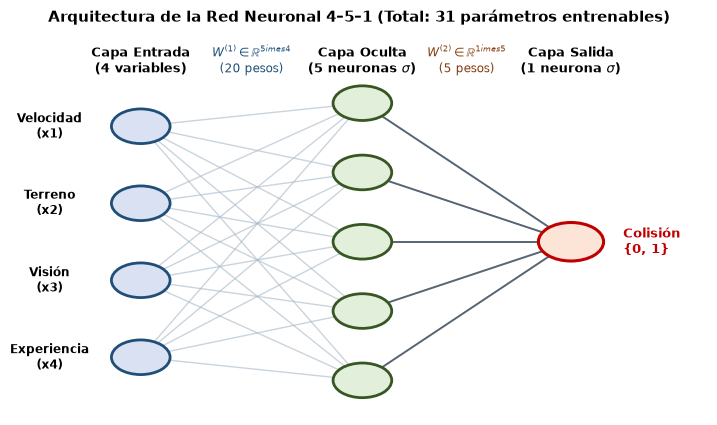

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.axis("off")

in_names = ["Velocidad\n(x1)", "Terreno\n(x2)", "Visión\n(x3)", "Experiencia\n(x4)"]
y_in = np.linspace(0.8, 0.2, 4)
y_hid = np.linspace(0.86, 0.14, 5)

# Dibujar conexiones W1 y W2
for yi in y_in:
    for yh in y_hid:
        ax.plot([0.18, 0.52], [yi, yh], color="#a6b8c7", lw=1.0, alpha=0.6)
for yh in y_hid:
    ax.plot([0.52, 0.84], [yh, 0.5], color="#2c3e50", lw=1.4, alpha=0.8)

# Nodos de entrada
for idx, yi in enumerate(y_in):
    c = plt.Circle((0.18, yi), 0.045, color="#d9e1f2", ec="#1f4e78", lw=2, zorder=4)
    ax.add_patch(c)
    ax.text(0.18, yi, f"$x_{idx+1}$", ha="center", va="center", fontsize=9.5, fontweight="bold")
    ax.text(0.04, yi, in_names[idx], ha="center", va="center", fontsize=8.5, fontweight="bold")

# Nodos ocultos
for idx, yh in enumerate(y_hid):
    c = plt.Circle((0.52, yh), 0.045, color="#e2efda", ec="#375623", lw=2, zorder=4)
    ax.add_patch(c)
    ax.text(0.52, yh, f"$a_{idx+1}^{{(1)}}$", ha="center", va="center", fontsize=9, fontweight="bold")

# Nodo de salida
c = plt.Circle((0.84, 0.5), 0.05, color="#fce4d6", ec="#c00000", lw=2.2, zorder=4)
ax.add_patch(c)
ax.text(0.84, 0.5, "$\hat{y}$", ha="center", va="center", fontsize=11, fontweight="bold")
ax.text(0.92, 0.5, "Colisión\n{0, 1}", ha="left", va="center", fontsize=9, fontweight="bold", color="#c00000")

# Etiquetas de capas
ax.text(0.18, 0.94, "Capa Entrada\n(4 variables)", ha="center", fontsize=9.5, fontweight="bold")
ax.text(0.35, 0.94, "$W^{(1)} \in \mathbb{R}^{5 \times 4}$\n(20 pesos)", ha="center", fontsize=8.5, color="#1f4e78")
ax.text(0.52, 0.94, "Capa Oculta\n(5 neuronas $\sigma$)", ha="center", fontsize=9.5, fontweight="bold")
ax.text(0.68, 0.94, "$W^{(2)} \in \mathbb{R}^{1 \times 5}$\n(5 pesos)", ha="center", fontsize=8.5, color="#833c0c")
ax.text(0.84, 0.94, "Capa Salida\n(1 neurona $\sigma$)", ha="center", fontsize=9.5, fontweight="bold")

ax.set_xlim(-0.02, 1.05)
ax.set_ylim(0.05, 1.05)
plt.title("Arquitectura de la Red Neuronal 4–5–1 (Total: 31 parámetros entrenables)", fontsize=11, fontweight="bold")
plt.show()


## 4. Inspección Neurona por Neurona de la Capa Oculta
Para entender cómo piensa la red, inspeccionamos qué calcula **cada una de las 5 neuronas ocultas** para el **Registro 1** (no choca) y el **Registro 2** (sí choca), reproduciendo exactamente las diapositivas 31 a 33 de clase:


In [4]:
# Escalamiento: x' = x / limites
X_escalado = escalar(X_RAW, LIMITES).T  # Transpuesto a (4, 7) para que las columnas sean ejemplos

print("--- REGISTRO 1 (Conductor Seguro: 65 km/h, Terreno 5, Visión 180°, Experiencia 80,000 km) ---")
x_reg1 = X_escalado[:, 0:1]
print("Entrada escalada x':", x_reg1.ravel().round(4))

z1_reg1 = W1 @ x_reg1 + B1
a1_reg1 = sigmoide(z1_reg1)
z2_reg1 = W2 @ a1_reg1 + B2
p_reg1  = sigmoide(z2_reg1)

print(f"{'Neurona':<8} | {'z_j^(1)':<12} | {'a_j^(1) = sigma(z_j^(1))':<24}")
print("-" * 50)
for j in range(5):
    print(f"Neurona {j+1} | {z1_reg1[j,0]:<+12.4f} | {a1_reg1[j,0]:<24.6f}")

print(f"\nSuma de salida z^(2): {z2_reg1[0,0]:.5f}")
print(f"Probabilidad de colisión p: {p_reg1[0,0]:.6f} -> (Clase predicha: {int(p_reg1[0,0] >= 0.5)}) [REAL = 0]")

print("\n" + "="*70 + "\n")

print("--- REGISTRO 2 (Conductor Peligroso: 120 km/h, Terreno 1, Visión 72°, Experiencia 110,000 km) ---")
x_reg2 = X_escalado[:, 1:2]
print("Entrada escalada x':", x_reg2.ravel().round(4))

z1_reg2 = W1 @ x_reg2 + B1
a1_reg2 = sigmoide(z1_reg2)
z2_reg2 = W2 @ a1_reg2 + B2
p_reg2  = sigmoide(z2_reg2)

print(f"{'Neurona':<8} | {'z_j^(1)':<12} | {'a_j^(1) = sigma(z_j^(1))':<24}")
print("-" * 50)
for j in range(5):
    print(f"Neurona {j+1} | {z1_reg2[j,0]:<+12.4f} | {a1_reg2[j,0]:<24.6f}")

print(f"\nSuma de salida z^(2): {z2_reg2[0,0]:.5f}")
print(f"Probabilidad de colisión p: {p_reg2[0,0]:.6f} -> (Clase predicha: {int(p_reg2[0,0] >= 0.5)}) [REAL = 1]")


--- REGISTRO 1 (Conductor Seguro: 65 km/h, Terreno 5, Visión 180°, Experiencia 80,000 km) ---
Entrada escalada x': [0.5417 0.5    0.5    0.2   ]
Neurona  | z_j^(1)      | a_j^(1) = sigma(z_j^(1))
--------------------------------------------------
Neurona 1 | -1.5404      | 0.176475                
Neurona 2 | +0.2328      | 0.557947                
Neurona 3 | -1.2728      | 0.218787                
Neurona 4 | +0.7708      | 0.683701                
Neurona 5 | +0.7938      | 0.688654                

Suma de salida z^(2): -6.19006
Probabilidad de colisión p: 0.002046 -> (Clase predicha: 0) [REAL = 0]


--- REGISTRO 2 (Conductor Peligroso: 120 km/h, Terreno 1, Visión 72°, Experiencia 110,000 km) ---
Entrada escalada x': [1.    0.1   0.2   0.275]
Neurona  | z_j^(1)      | a_j^(1) = sigma(z_j^(1))
--------------------------------------------------
Neurona 1 | +1.7417      | 0.850909                
Neurona 2 | -2.6603      | 0.065360                
Neurona 3 | +1.2503      | 0.777343  

## 5. Evaluación de los 7 Registros en Lote y Métricas Oficiales
Ejecutamos la propagación matricial completa por lote y verificamos contra las etiquetas reales:


In [5]:
# Propagación de todos los 7 registros en una sola operación matricial
Z1, A1, Z2, P = propagar(X_escalado, W1, B1, W2, B2)

print(f"Forma de la matriz de salida P: {P.shape} (1 fila x 7 ejemplos)")

# Aserciones numéricas exigidas en el taller
assert P.shape == (1, 7), 'Revisar forma de salida'
assert np.allclose(P[0, :2], [0.002046, 0.999962], atol=1e-6), 'Verificación numérica fallida'

# Comparar lote vs individual
individual = np.hstack([propagar(X_escalado[:, i:i+1], W1, B1, W2, B2)[3] for i in range(7)])
assert np.allclose(P, individual), 'Lote e individual difieren'

# Clasificación con umbral estándar 0.5
C = clasificar(P, umbral=0.5).ravel()

print("\n" + "="*65)
print(f"{'Reg':<4} | {'Velocidad':<10} | {'Terreno':<8} | {'Visión':<7} | {'Experiencia':<11} | {'y':<3} | {'Puntaje P':<10} | {'Clase':<5} | {'Acierto'}")
print("="*65)
for i in range(7):
    v, t, vis, exp = X_RAW[i]
    print(f"{i+1:<4} | {v:<10.0f} | {t:<8.0f} | {vis:<7.0f} | {exp:<11.0f} | {Y[i]:<3} | {P[0, i]:<10.6f} | {C[i]:<5} | {C[i] == Y[i]}")

acc = np.mean(C == Y)
bce = entropia_cruzada(Y, P)

print("\n" + "-"*40)
print(f"Exactitud didáctica (Accuracy): {acc * 100:.1f}%")
print(f"Pérdida media de Entropía Cruzada: {bce:.8f}")
print("-"*40)

print("\nEvaluación con diferentes umbrales tau:")
for t in [0.3, 0.5, 0.8]:
    pred_t = clasificar(P, umbral=t).ravel()
    print(f"  Umbral tau = {t}: {pred_t} (Aciertos: {np.sum(pred_t == Y)}/7)")

print("\n¡Todas las verificaciones del taller fueron superadas con éxito!")


Forma de la matriz de salida P: (1, 7) (1 fila x 7 ejemplos)

Reg  | Velocidad  | Terreno  | Visión  | Experiencia | y   | Puntaje P  | Clase | Acierto
1    | 65         | 5        | 180     | 80000       | 0   | 0.002046   | 0     | True
2    | 120        | 1        | 72      | 110000      | 1   | 0.999962   | 1     | True
3    | 8          | 6        | 288     | 50000       | 0   | 0.000008   | 0     | True
4    | 50         | 2        | 324     | 1600        | 1   | 0.999182   | 1     | True
5    | 25         | 9        | 36      | 160000      | 0   | 0.000001   | 0     | True
6    | 80         | 3        | 120     | 6000        | 1   | 0.997698   | 1     | True
7    | 40         | 3        | 360     | 400000      | 0   | 0.000002   | 0     | True

----------------------------------------
Exactitud didáctica (Accuracy): 100.0%
Pérdida media de Entropía Cruzada: 0.00074555
----------------------------------------

Evaluación con diferentes umbrales tau:
  Umbral tau = 0.3: [0 1 0 1 0

## 6. Experimentos de Sensibilidad: ¿Qué pasa al variar Velocidad o Experiencia?
Tomamos un registro base (65 km/h, terreno 5, visión 180°, experiencia 80,000 km) y evaluamos cómo responde la red neuronal variando una sola característica (*Ceteris Paribus*):


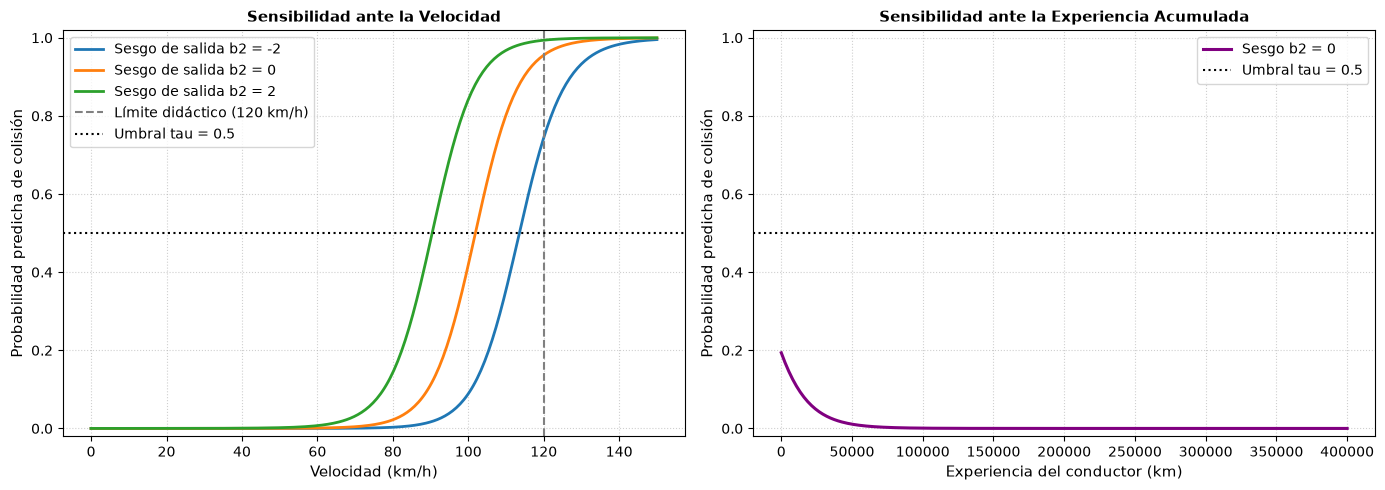

In [6]:
def curva_sensibilidad(valores, columna, sesgo=0.0):
    """Genera predicciones variando una columna sobre el registro base."""
    base = np.array([65.0, 5.0, 180.0, 80000.0])
    lote_raw = np.tile(base, (len(valores), 1))
    lote_raw[:, columna] = valores
    X_esc = (lote_raw / LIMITES).T
    b2_local = np.array([[float(sesgo)]])
    _, _, _, p_out = propagar(X_esc, W1, B1, W2, b2_local)
    return p_out.ravel()

# EXPERIMENTO 1: VARIAR VELOCIDAD (0 a 150 km/h) CON DISTINTOS SESGOS
v = np.linspace(0, 150, 300)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for b in [-2, 0, 2]:
    ax1.plot(v, curva_sensibilidad(v, columna=0, sesgo=b), label=f'Sesgo de salida b2 = {b}', lw=2)

ax1.axvline(120, color='gray', linestyle='--', label='Límite didáctico (120 km/h)')
ax1.axhline(0.5, color='black', linestyle=':', label='Umbral tau = 0.5')
ax1.set_xlabel('Velocidad (km/h)', fontsize=10.5)
ax1.set_ylabel('Probabilidad predicha de colisión', fontsize=10.5)
ax1.set_title('Sensibilidad ante la Velocidad', fontsize=11, fontweight='bold')
ax1.set_ylim(-0.02, 1.02)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# EXPERIMENTO 2: VARIAR EXPERIENCIA (0 a 400.000 km)
e = np.linspace(0, 400000, 300)
ax2.plot(e, curva_sensibilidad(e, columna=3, sesgo=0.0), color='purple', lw=2.2, label='Sesgo b2 = 0')
ax2.axhline(0.5, color='black', linestyle=':', label='Umbral tau = 0.5')
ax2.set_xlabel('Experiencia del conductor (km)', fontsize=10.5)
ax2.set_ylabel('Probabilidad predicha de colisión', fontsize=10.5)
ax2.set_title('Sensibilidad ante la Experiencia Acumulada', fontsize=11, fontweight='bold')
ax2.set_ylim(-0.02, 1.02)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


## 7. Reto Opcional: ¿Por qué una sola neurona no puede resolver XOR?
En una compuerta XOR, las clases positivas $(0, 1)$ y $(1, 0)$ quedan en esquinas opuestas, por lo que ninguna línea recta puede separarlas.
Aquí demostramos cómo dos neuronas ocultas ($h_1$ simulando un OR y $h_2$ simulando un AND con función escalón de Heaviside) resuelven el problema:


In [7]:
def H(z):
    """Función escalón unitario de Heaviside: 1 si z >= 0, sino 0."""
    return (np.asarray(z) >= 0.0).astype(int)

entradas = [(0, 0), (0, 1), (1, 0), (1, 1)]
print(f"{'Entrada':<10} | {'h1 = H(x1+x2-0.5) [OR]':<25} | {'h2 = H(x1+x2-1.5) [AND]':<25} | {'y_hat = H(h1-2h2-0.5)':<22} | {'XOR Real'}")
print("-" * 95)
for x1, x2 in entradas:
    h1 = H(x1 + x2 - 0.5)
    h2 = H(x1 + x2 - 1.5)
    y_pred = H(h1 - 2 * h2 - 0.5)
    xor_real = x1 ^ x2
    print(f"({x1}, {x2})     | {h1:<25} | {h2:<25} | {y_pred:<22} | {xor_real}")


Entrada    | h1 = H(x1+x2-0.5) [OR]    | h2 = H(x1+x2-1.5) [AND]   | y_hat = H(h1-2h2-0.5)  | XOR Real
-----------------------------------------------------------------------------------------------
(0, 0)     | 0                         | 0                         | 0                      | 0
(0, 1)     | 1                         | 0                         | 1                      | 1
(1, 0)     | 1                         | 0                         | 1                      | 1
(1, 1)     | 1                         | 1                         | 0                      | 0
